In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

import warnings
warnings.filterwarnings("ignore")

In [2]:
!wget -q https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip
!unzip -q "individual+household+electric+power+consumption.zip"

In [3]:
df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values="?",
    low_memory=False
)

df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [4]:
df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True
)

df.set_index("Datetime", inplace=True)

df.drop(columns=["Date", "Time"], inplace=True)

df = df.apply(pd.to_numeric, errors="coerce")
df = df.interpolate()

df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [5]:
data = df[["Global_active_power"]].copy()

In [6]:
hourly_data = data.resample("H").mean()

hourly_data.head()

,Global_active_power
Datetime,
2006-12-16 17:00:00,4.222889
2006-12-16 18:00:00,3.632200
2006-12-16 19:00:00,3.400233
2006-12-16 20:00:00,3.268567
2006-12-16 21:00:00,3.056467


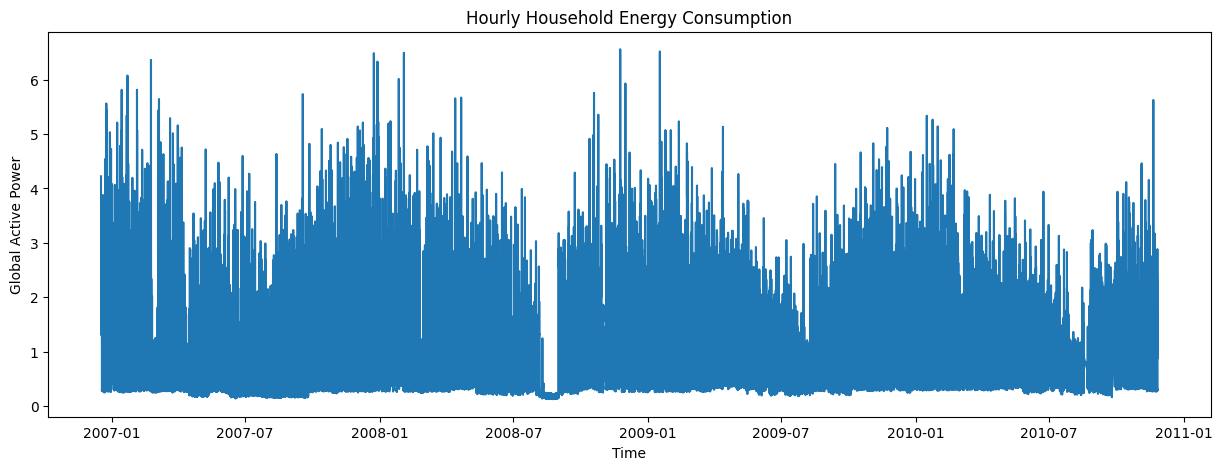

In [7]:
plt.figure(figsize=(15,5))
plt.plot(hourly_data)
plt.title("Hourly Household Energy Consumption")
plt.xlabel("Time")
plt.ylabel("Global Active Power")
plt.show()

In [8]:
values = hourly_data.values

train_size = int(len(values) * 0.8)

train = values[:train_size]
test = values[train_size:]

In [9]:
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train)
test_scaled = scaler.transform(test)

In [10]:
def create_sequences(data, window=24):
    X = []
    y = []

    for i in range(window, len(data)):
        X.append(data[i-window:i])
        y.append(data[i])

    return np.array(X), np.array(y)

In [11]:
X_train, y_train = create_sequences(train_scaled, 24)
X_test, y_test = create_sequences(test_scaled, 24)

print(X_train.shape)
print(y_train.shape)

(27647, 24, 1)
(27647, 1)


In [12]:
model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(24, 1)),
    Dropout(0.2),

    LSTM(32),
    Dropout(0.2),

    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,345 (114.63 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
778/778 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - loss: 0.0129 - val_loss: 0.0106
Epoch 2/20
778/778 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0101 - val_loss: 0.0096
Epoch 3/20
778/778 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - loss: 0.0095 - val_loss: 0.0097
Epoch 4/20
778/778 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0092 - val_loss: 0.0094
Epoch 5/20
778/778 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0090 - val_loss: 0.0097
Epoch 6/20
778/778 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0090 - val_loss: 0.0090
Epoch 7/20
778/778 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0089 - val_loss: 0.0091
Epoch 8/20
778/778 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0088 - val_loss: 0.0092
Epoch 9/20
778/778 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0088 - val_loss: 0.0089
Epoch 10/20
778/778 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0088 - val_loss: 0.0090
Epoch 11/20
778/778 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - loss: 0.0088 - val_loss: 0.0093
Epoch 12/20
778/778 ━━━━━━━━━━

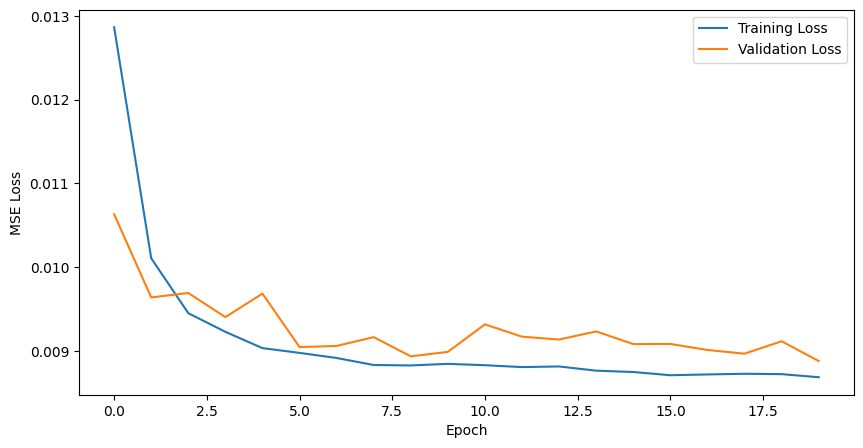

In [14]:
plt.figure(figsize=(10,5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()

In [15]:
pred_scaled = model.predict(X_test)

pred = scaler.inverse_transform(pred_scaled)
actual = scaler.inverse_transform(y_test)

216/216 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [16]:
mae = mean_absolute_error(actual, pred)

rmse = np.sqrt(
    mean_squared_error(actual, pred)
)

mape = np.mean(
    np.abs((actual - pred) / np.maximum(np.abs(actual), 1e-8))
) * 100

print("LSTM MAE :", mae)
print("LSTM RMSE:", rmse)
print("LSTM MAPE:", mape)

LSTM MAE : 0.35303676003253487
LSTM RMSE: 0.5025566549741722
LSTM MAPE: 48.30163067045567


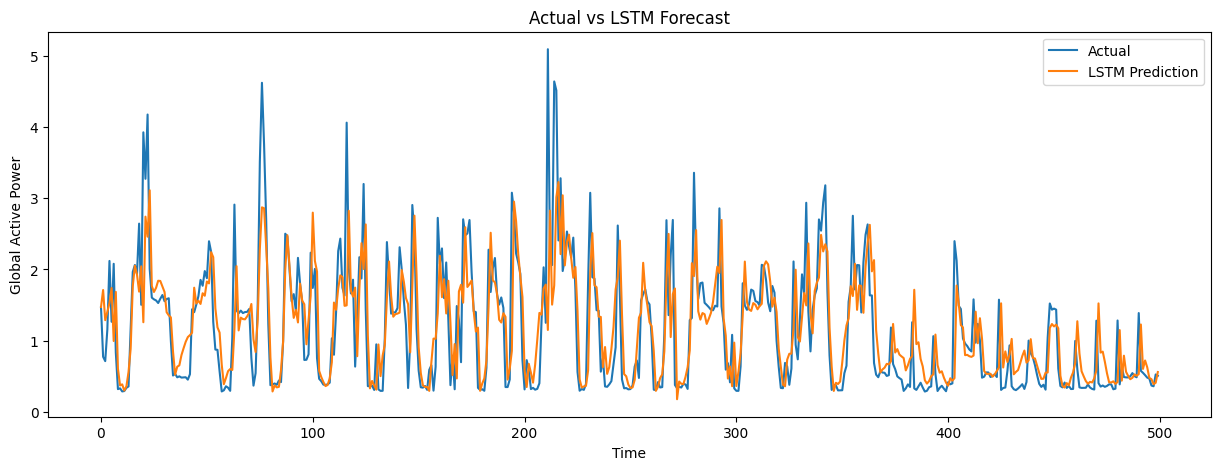

In [17]:
plt.figure(figsize=(15,5))

plt.plot(actual[:500], label="Actual")
plt.plot(pred[:500], label="LSTM Prediction")

plt.title("Actual vs LSTM Forecast")
plt.xlabel("Time")
plt.ylabel("Global Active Power")
plt.legend()

plt.show()

In [18]:
!pip -q install statsmodels

In [19]:
from statsmodels.tsa.arima.model import ARIMA

In [20]:
train_arima = train.flatten()
test_arima = test.flatten()

history_arima = list(train_arima)

predictions_arima = []

for value in test_arima[:500]:
    model_arima = ARIMA(history_arima, order=(5,1,0))
    fitted = model_arima.fit()

    forecast = fitted.forecast()[0]

    predictions_arima.append(forecast)
    history_arima.append(value)

In [21]:
arima_actual = test_arima[:500]

arima_mae = mean_absolute_error(
    arima_actual,
    predictions_arima
)

arima_rmse = np.sqrt(
    mean_squared_error(
        arima_actual,
        predictions_arima
    )
)

arima_mape = np.mean(
    np.abs(
        (arima_actual - predictions_arima) /
        np.maximum(np.abs(arima_actual), 1e-8)
    )
) * 100

print("ARIMA MAE :", arima_mae)
print("ARIMA RMSE:", arima_rmse)
print("ARIMA MAPE:", arima_mape)

ARIMA MAE : 0.4383007780126852
ARIMA RMSE: 0.6713978333757674
ARIMA MAPE: 46.93616583676167


In [22]:
results = pd.DataFrame({
    "Model": ["LSTM", "ARIMA"],
    "MAE": [mae, arima_mae],
    "RMSE": [rmse, arima_rmse],
    "MAPE (%)": [mape, arima_mape]
})

results

,Model,MAE,RMSE,MAPE (%)
0,LSTM,0.353037,0.502557,48.301631
1,ARIMA,0.438301,0.671398,46.936166
